# Review the logist function

$$\sigma(x)=\frac{1}{1+e^{-x}}$$

In [2]:
import numpy as np 
import matplotlib.pyplot as plt

In [3]:
def sigmoid(x):
    sig = 1/(1+np.exp(-x+18))
    return sig

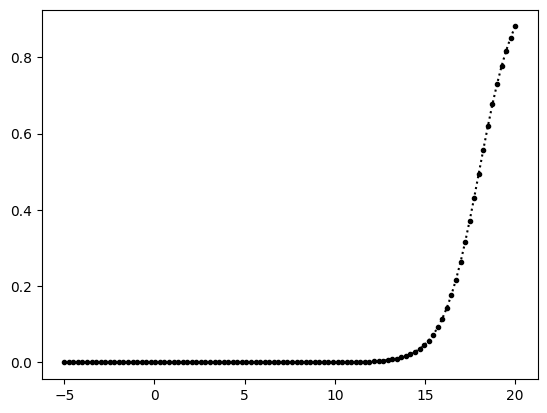

In [4]:
x = np.linspace(-5, 20, 100)
y = sigmoid(x)
plt.plot(x,y,'.:k')
plt.show()

# Exploring the iris dataset

In [5]:
import pandas as pd
df = pd.read_csv('iris_basic.csv')
df

,sl,sw,pl,pw,target,tNames
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa
...,...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2,virginica
146,6.3,2.5,5.0,1.9,2,virginica
147,6.5,3.0,5.2,2.0,2,virginica
148,6.2,3.4,5.4,2.3,2,virginica


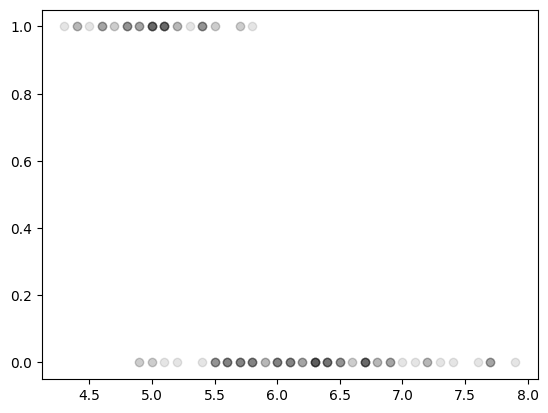

In [6]:
x1 = df['sl']
y = df['target'].to_numpy().reshape(-1,1)
y = (y==0).astype(float)
plt.plot(x1,y,'ok', alpha=0.1)
plt.show()

# One parameter LR Model
Log loss:
$$-\frac{1}{m}\sum{y\cdot \log{(p)}+(1-y)\cdot \log{(1-p)}}$$

In [7]:
# model function Sigmoid
# def sigmoid ...

# J
def LogLoss(y,p):
    return -np.mean(y*np.log(p)+(1-y)*np.log(1-p))

In [8]:
# hyperparameters:
eta = 0.1
epoch = 500000 # n
X = np.column_stack([np.ones_like(x1), x1]) # np.c_[np.ones(x1), x1]
m = X.shape[0]
np.random.seed(99)
thetaH = np.random.rand(2,1)
thetaH

array([[0.67227856],
       [0.4880784 ]])

In [9]:
# Batch Gradient Descent
J = np.zeros((epoch,1))
for i in range(epoch):
    z = X@thetaH
    h = sigmoid(z)
    J[i] = LogLoss(y,h)
    nabla = (X.T@(h-y))/m
    #thetaH = thetaH - eta*nabla
    thetaH -= eta*nabla
thetaH

array([[45.82851102],
       [-5.17569621]])

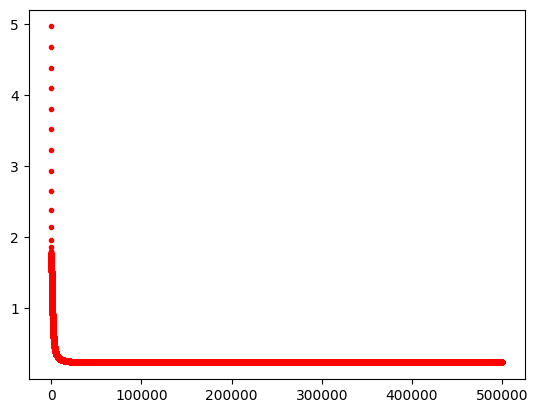

In [10]:
plt.plot(J,'.r')
plt.show()

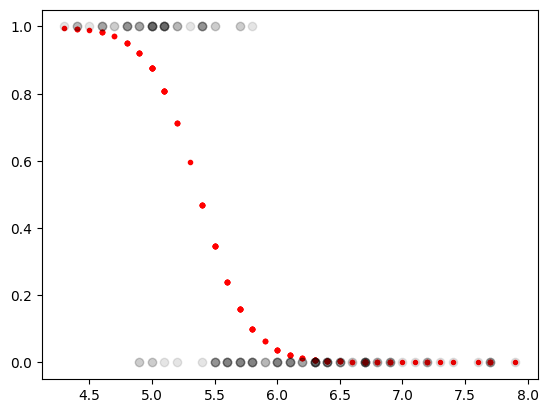

In [11]:
yM = sigmoid(X@thetaH)
plt.plot(x1, yM, '.r')
plt.plot(x1,y,'ok', alpha=0.1)
plt.show()

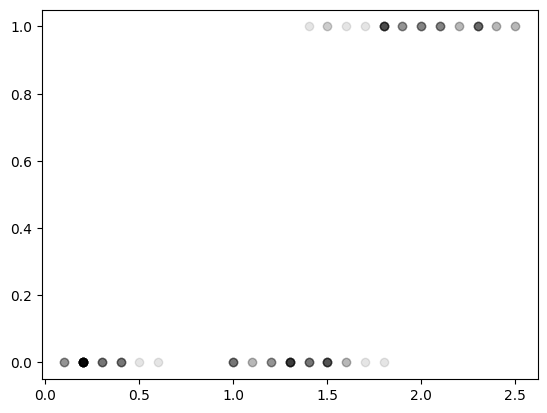

In [12]:
# points
x1 = df['pw']
y = df['target'].to_numpy().reshape(-1,1)
y = (y==2).astype(float)
plt.plot(x1,y,'ok', alpha=0.1)
plt.show()

In [13]:
# hyperparameters:
eta = 0.1
epoch = 500000 # n
X = np.column_stack([np.ones_like(x1), x1]) # np.c_[np.ones(x1), x1]
m = X.shape[0]
np.random.seed(99)
thetaH = np.random.rand(2,1)
thetaH

array([[0.67227856],
       [0.4880784 ]])

In [14]:
# Batch Gradient Descent
J = np.zeros((epoch,1))
for i in range(epoch):
    z = X@thetaH
    h = sigmoid(z)
    J[i] = LogLoss(y,h)
    nabla = (X.T@(h-y))/m
    #thetaH = thetaH - eta*nabla
    thetaH -= eta*nabla
thetaH

array([[-3.12558839],
       [12.94747533]])

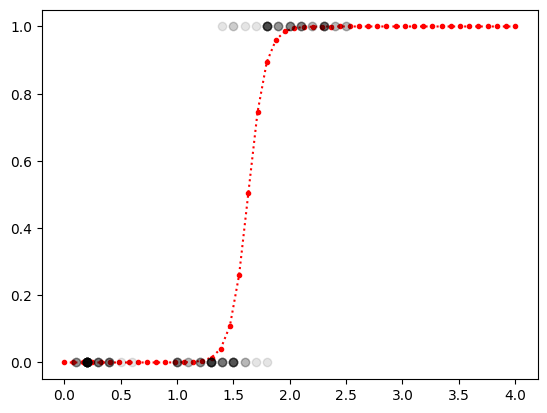

In [15]:
x1New = np.linspace(0,4,50)
XNew = np.column_stack([np.ones_like(x1New), x1New])
zNew = XNew@thetaH
yM = sigmoid(zNew)
plt.plot(x1New, yM, '.:r')
plt.plot(x1,y,'ok', alpha=0.1)
plt.show()

# Two-Parameters LR Model

In [16]:
x1 = df['sl'].to_numpy()
x2 = df['sw'].to_numpy()
X = np.column_stack([np.ones_like(x1), x1, x2])
y = df['target'].to_numpy()#.reshape(-1,1)

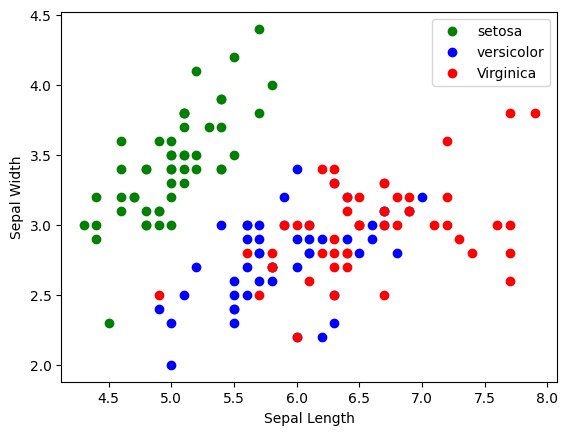

In [17]:
plt.plot(x1[y==0], x2[y==0], 'og', label='setosa')
plt.plot(x1[y==1], x2[y==1], 'ob', label='versicolor')
plt.plot(x1[y==2], x2[y==2], 'or', label='Virginica')
plt.xlabel('Sepal Length')
plt.ylabel('Sepal Width')
plt.legend()
plt.show()

In [19]:
#Hyper parameters
eta = 0.01 
m = len(x1)
epoch = 100000
thetaH = np.random.rand(3,1)
thetaH
print(thetaH.shape)
print(thetaH)

(3, 1)
[[0.56561742]
 [0.2976225 ]
 [0.04669572]]


In [23]:
#yH = sigmoid(theta0+theta1*x1+theta2*x2)
yH = X@thetaH
y = df['target'].to_numpy().reshape(-1,1)
y = (y==0).astype(float)
print(y[0:9])

[[1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]
 [1.]]


In [24]:
J = np.zeros((epoch,1))
for i in range(epoch):
    z = X@thetaH
    p = sigmoid(z)
    J[i] = LogLoss(y,p)
    nabla = (X.T@(p-y))/m
    thetaH = thetaH-eta*nabla

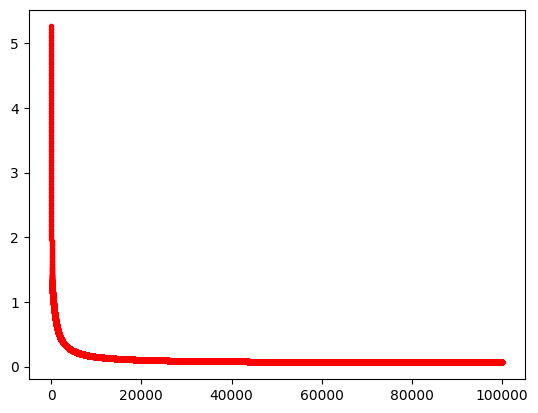

(3, 1)

In [25]:
plt.plot(J,'.r')
plt.show()
thetaH.shape

In [26]:
x1New, x2New = np.meshgrid(
    np.linspace(3,8, 100).reshape(-1,1),
    np.linspace(1.5,5,100).reshape(-1,1)
)
XNew = np.column_stack([np.ones_like(x1New.ravel()), x1New.ravel(), x2New.ravel()])
yP = sigmoid(XNew@thetaH).reshape(x1New.shape)

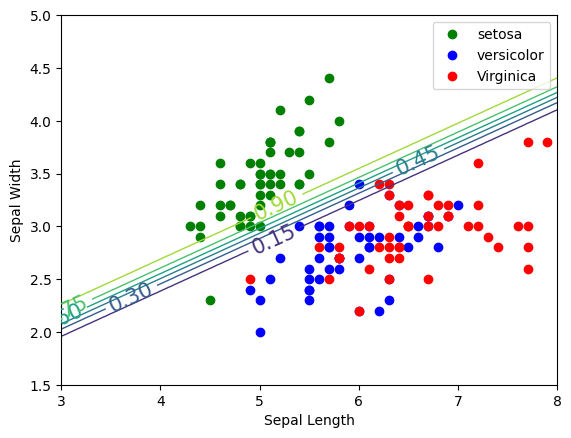

In [27]:
y = df['target'].to_numpy()
plt.plot(x1[y==0], x2[y==0], 'og', label='setosa')
plt.plot(x1[y==1], x2[y==1], 'ob', label='versicolor')
plt.plot(x1[y==2], x2[y==2], 'or', label='Virginica')
contour = plt.contour(x1New, x2New, yP, linewidths=1)
plt.clabel(contour, inline=1, fontsize=15)
plt.xlabel('Sepal Length')
plt.ylabel('Sepal Width')
plt.legend()
plt.show()

# Multi-parametric LR Model